# Problema 4 – Classificação de Risco de Crédito Utilizando Árvores de Decisão

PAM0466 – Sistemas Inteligentes

A concessão de crédito é uma das decisões mais sensíveis do sistema financeiro: aprovar um cliente inadimplente gera prejuízo direto, mas recusar um bom pagador significa perda de receita e exclusão financeira. Diferentemente de outras aplicações de machine learning, aqui não basta acertar, é preciso justificar a decisão. A LGPD (Lei 13.709/2018), em seu Art. 20, assegura ao titular o direito de solicitar a revisão de decisões tomadas exclusivamente com base em tratamento automatizado, o que torna modelos interpretáveis especialmente valiosos nesse domínio.

É exatamente esse o apelo da árvore de decisão: o modelo aprendido pode ser lido como um conjunto de regras de produção, uma explicação que um analista, um cliente ou um auditor consegue compreender sem conhecimento de estatística. No Brasil, iniciativas como o Cadastro Positivo, o Open Finance e programas de microcrédito produtivo orientado como o Crediamigo, do Banco do Nordeste, dependem de avaliações de risco em larga escala, tornando o problema próximo da nossa realidade.

Neste projeto, você é convidado a construir um modelo de classificação de solicitantes de crédito em duas categorias de risco (bom pagador e mau pagador) a partir de dados cadastrais e financeiros, utilizando uma Árvore de Decisão (Decision Tree).

O projeto utiliza o arquivo german.data do dataset Statlog (German Credit Data) (https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data). O dataset foi doado por Hans Hofmann (Universidade de Hamburgo, Alemanha) em 1994 e reúne 1.000 solicitações de crédito reais de um banco alemão. Cada amostra é descrita por 20 atributos: 7 numéricos e 13 categóricos. Entre os atributos, temos duração do empréstimo em meses, valor solicitado, histórico de crédito, finalidade do empréstimo, saldo em conta corrente, tempo de emprego atual, idade, número de créditos ativos e existência de garantias. O rótulo indica se o cliente representou, de fato, um bom risco (700 amostras) ou um mau risco (300 amostras) de crédito.

Observação: os atributos categóricos do arquivo german.data aparecem codificados (A11, A12, ...), com o significado de cada código descrito no arquivo german.doc. Alternativamente, a versão com rótulos legíveis pode ser obtida diretamente via: sklearn.datasets.fetch_openml(name='credit-g', version=1).

Realize as seguintes tarefas utilizando o dataset fornecido:

1. Preparação dos dados: carregue o dataset, identifique quais atributos são numéricos e quais são categóricos. Verifique se existe necessidade de codificação adequada às variáveis categóricas (one-hot encoding ou ordinal encoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado (70%/30%) sobre a interpretação da acurácia.
2. Justifique por que a normalização dos atributos não é necessária para uma árvore de decisão.
3. Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das duas classes seja mantida em ambos os conjuntos.
4. Treinamento e controle de complexidade: treine árvores com diferentes valores de profundidade máxima (ex: 2, 3, 5, 7, 10 e sem limite), utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade, e escolha o valor com melhor desempenho. O que acontece com o modelo para profundidades muito baixas e muito altas? Relacione sua resposta aos conceitos de underfitting e overfitting. Repita o experimento trocando o critério de divisão dos nós de Gini para entropia e comente se houve diferença relevante.
5. Interpretação do modelo: usando a árvore com a profundidade escolhida, gere a visualização gráfica da árvore e a lista de importância dos atributos. Responda: quais são os três atributos mais determinantes para a classificação? Escreva, em linguagem natural, o conjunto de regras correspondente ao caminho que leva da raiz até a folha com maior número de amostras de mau risco.
6. Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: qual tipo de erro o modelo comete com mais frequência e por que ele é o mais grave nesta aplicação? Que ajuste você faria no treinamento para reduzi-lo?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

SEED = 42   # semente usada em todo o notebook (divisão, validação cruzada e árvores)

In [2]:
# o arquivo german.data não tem cabeçalho: damos nome às 20 colunas + o rótulo (target)
colunas = ["status", "duration", "credit_history", "purpose", "amount", "savings",
           "employment", "installment_rate", "personal_status", "other_debtors",
           "residence_since", "property", "age", "other_installment_plans", "housing",
           "num_credits", "job", "people_liable", "telephone", "foreign_worker", "target"]

# colunas separadas por espaço (sep=r"[,\s]+" aceita espaços e vírgulas)
df = pd.read_csv('german_questao4.data', sep=r"[,\s]+", engine="python", header=None, names=colunas)
print('Formato (amostras, colunas):', df.shape)
df.head()

Formato (amostras, colunas): (1000, 21)


,status,duration,credit_history,purpose,amount,savings,employment,installment_rate,personal_status,other_debtors,...,property,age,other_installment_plans,housing,num_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
# os atributos categóricos vêm codificados (A11, A12, ...). Trocamos cada código pelo seu
# significado, conforme a descrição do arquivo german.doc
dic = {
 "status": {"A11": "< 0 DM", "A12": "0 a 200 DM", "A13": ">= 200 DM / salário", "A14": "sem conta corrente"},
 "credit_history": {"A30": "nenhum crédito/todos pagos", "A31": "todos pagos neste banco",
                    "A32": "créditos existentes pagos em dia", "A33": "atraso no passado",
                    "A34": "conta crítica/outros créditos"},
 "purpose": {"A40": "carro novo", "A41": "carro usado", "A42": "móveis/equipamentos", "A43": "rádio/TV",
             "A44": "eletrodomésticos", "A45": "reparos", "A46": "educação", "A47": "férias",
             "A48": "requalificação", "A49": "negócios", "A410": "outros"},
 "savings": {"A61": "< 100 DM", "A62": "100 a 500 DM", "A63": "500 a 1000 DM", "A64": ">= 1000 DM", "A65": "desconhecida/sem poupança"},
 "employment": {"A71": "desempregado", "A72": "< 1 ano", "A73": "1 a 4 anos", "A74": "4 a 7 anos", "A75": ">= 7 anos"},
 "personal_status": {"A91": "homem div./sep.", "A92": "mulher div./sep./casada", "A93": "homem solteiro",
                     "A94": "homem casado/viúvo", "A95": "mulher solteira"},
 "other_debtors": {"A101": "nenhum", "A102": "co-solicitante", "A103": "fiador"},
 "property": {"A121": "imóvel", "A122": "poupança-habitação/seguro de vida", "A123": "carro/outro", "A124": "desconhecido/sem bens"},
 "other_installment_plans": {"A141": "banco", "A142": "lojas", "A143": "nenhum"},
 "housing": {"A151": "aluguel", "A152": "própria", "A153": "gratuita"},
 "job": {"A171": "desempregado/não qualificado não residente", "A172": "não qualificado residente",
         "A173": "qualificado/funcionário", "A174": "gerência/autônomo/altamente qualificado"},
 "telephone": {"A191": "não", "A192": "sim"},
 "foreign_worker": {"A201": "sim", "A202": "não"},
}
for col, m in dic.items():
    df[col] = df[col].map(m)

# rótulo: no arquivo 1 = bom e 2 = mau. Aqui: 0 = bom pagador, 1 = mau pagador (classe positiva)
y = (df["target"] == 2).astype(int)
X_raw = df.drop(columns="target")

print('Valores ausentes:', int(df.isna().sum().sum()))
X_raw.head()

Valores ausentes: 0


,status,duration,credit_history,purpose,amount,savings,employment,installment_rate,personal_status,other_debtors,residence_since,property,age,other_installment_plans,housing,num_credits,job,people_liable,telephone,foreign_worker
0,< 0 DM,6,conta crítica/outros créditos,rádio/TV,1169,desconhecida/sem poupança,>= 7 anos,4,homem solteiro,nenhum,4,imóvel,67,nenhum,própria,2,qualificado/funcionário,1,sim,sim
1,0 a 200 DM,48,créditos existentes pagos em dia,rádio/TV,5951,< 100 DM,1 a 4 anos,2,mulher div./sep./casada,nenhum,2,imóvel,22,nenhum,própria,1,qualificado/funcionário,1,não,sim
2,sem conta corrente,12,conta crítica/outros créditos,educação,2096,< 100 DM,4 a 7 anos,2,homem solteiro,nenhum,3,imóvel,49,nenhum,própria,1,não qualificado residente,2,não,sim
3,< 0 DM,42,créditos existentes pagos em dia,móveis/equipamentos,7882,< 100 DM,4 a 7 anos,2,homem solteiro,fiador,4,poupança-habitação/seguro de vida,45,nenhum,gratuita,1,qualificado/funcionário,2,não,sim
4,< 0 DM,24,atraso no passado,carro novo,4870,< 100 DM,1 a 4 anos,3,homem solteiro,nenhum,4,desconhecido/sem bens,53,nenhum,gratuita,2,qualificado/funcionário,2,não,sim


## Tarefa 1 - Preparação dos dados: carregue o dataset, identifique quais atributos são numéricos e quais são categóricos. Verifique se existe necessidade de codificação adequada às variáveis categóricas (one-hot encoding ou ordinal encoding). Avalie o balanceamento entre as classes e comente o impacto de um conjunto desbalanceado (70%/30%) sobre a interpretação da acurácia.

In [4]:
# separa atributos numéricos e categóricos pelo tipo de dado de cada coluna
num_cols = X_raw.select_dtypes(include="number").columns.tolist()
cat_cols = X_raw.select_dtypes(exclude="number").columns.tolist()

print(f"Numéricos   ({len(num_cols)}): {num_cols}")
print(f"Categóricos ({len(cat_cols)}): {cat_cols}")
print()
# quantidade de categorias distintas de cada atributo categórico
print(X_raw[cat_cols].nunique().sort_values(ascending=False).to_string())

Numéricos   (7): ['duration', 'amount', 'installment_rate', 'residence_since', 'age', 'num_credits', 'people_liable']
Categóricos (13): ['status', 'credit_history', 'purpose', 'savings', 'employment', 'personal_status', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']

purpose                    10
savings                     5
credit_history              5
employment                  5
status                      4
personal_status             4
property                    4
job                         4
other_debtors               3
other_installment_plans     3
housing                     3
telephone                   2
foreign_worker              2


O `scikit-learn` só trabalha com números, então as categorias em texto precisam ser codificadas. Duas opções:

- **One-hot:** cria uma coluna 0/1 para cada categoria; adequada para categorias **sem ordem** (finalidade do empréstimo, estado civil);
- **Ordinal:** troca a categoria por 0, 1, 2, ...; adequada para categorias com ordem natural.

Será usado **one-hot** em todas as categóricas: a maioria é nominal e, mesmo as quase ordinais (conta corrente, poupança, emprego), têm uma categoria fora da escala ("sem conta corrente", "desconhecida"). Além disso, o one-hot gera regras de fácil leitura na árvore (por exemplo, `status = 'sem conta corrente'`).

In [5]:
# one-hot encoding: cada categoria vira uma coluna 0/1 (dtype=int)
X = pd.get_dummies(X_raw, columns=cat_cols, prefix_sep=" = ", dtype=int)
print("Formato antes:", X_raw.shape, "| depois do one-hot:", X.shape)
X.iloc[:3, :8]

Formato antes: (1000, 20) | depois do one-hot: (1000, 61)


,duration,amount,installment_rate,residence_since,age,num_credits,people_liable,status = 0 a 200 DM
0,6,1169,4,4,67,2,1,0
1,48,5951,2,2,22,1,1,1
2,12,2096,2,3,49,1,2,0


                 quantidade  proporção
target                                
bom pagador (0)         700        0.7
mau pagador (1)         300        0.3

Acurácia de um modelo que SEMPRE diz 'bom pagador': 70.00%


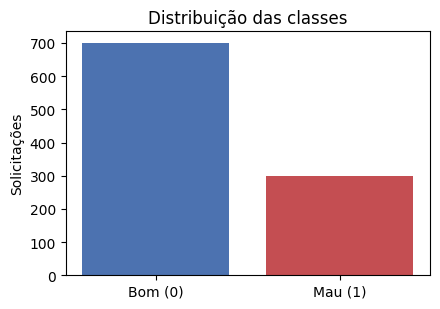

In [6]:
# balanceamento das classes
contagem = y.map({0: "bom pagador (0)", 1: "mau pagador (1)"}).value_counts()
print(pd.DataFrame({'quantidade': contagem, 'proporção': (contagem / len(y)).round(3)}))
print()
# acurácia de um modelo "bobo" que aprova todos os clientes (sempre prevê bom pagador)
print(f"Acurácia de um modelo que SEMPRE diz 'bom pagador': {(y == 0).mean():.2%}")

plt.figure(figsize=(4.5, 3.2))
plt.bar(["Bom (0)", "Mau (1)"], [(y == 0).sum(), (y == 1).sum()], color=["#4C72B0", "#C44E52"])
plt.title("Distribuição das classes"); plt.ylabel("Solicitações")
plt.tight_layout()
plt.show()

**Resposta.**
- **Numéricos (7):** `duration`, `amount`, `installment_rate`, `residence_since`, `age`, `num_credits`, `people_liable`.
- **Categóricos (13):** `status`, `credit_history`, `purpose`, `savings`, `employment`, `personal_status`, `other_debtors`, `property`, `other_installment_plans`, `housing`, `job`, `telephone`, `foreign_worker`. Não há valores ausentes.
- **Codificação:** é necessária, porque o scikit-learn não aceita texto. Foi usado **one-hot** (61 colunas no final), pelos motivos acima.
- **Balanceamento:** 700 bons (70%) e 300 maus (30%). Um modelo que **aprova todo mundo** acerta 70% sem aprender nada, então a acurácia sozinha engana: uma acurácia de 70% não é desempenho, é o piso. Além disso, a acurácia trata igual dois erros de custos muito diferentes (aprovar um mau pagador custa muito mais que recusar um bom), por isso é preciso olhar também precisão e recall da classe "mau".

## Tarefa 2 - Justifique por que a normalização dos atributos não é necessária para uma árvore de decisão.

In [7]:
from sklearn.preprocessing import StandardScaler

# experimento: a mesma árvore treinada nos dados originais e nos dados padronizados (Z-score)
Xtr_a, Xte_a, ytr_a, yte_a = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

arv_original = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(Xtr_a, ytr_a)

sc = StandardScaler().fit(Xtr_a)
arv_zscore = DecisionTreeClassifier(max_depth=5, random_state=SEED).fit(sc.transform(Xtr_a), ytr_a)

p1 = arv_original.predict(Xte_a)
p2 = arv_zscore.predict(sc.transform(Xte_a))
print("Previsões idênticas com e sem normalização:", bool((p1 == p2).all()))
print(f"Acurácia sem normalização: {accuracy_score(yte_a, p1):.4f} | com Z-score: {accuracy_score(yte_a, p2):.4f}")

Previsões idênticas com e sem normalização: True
Acurácia sem normalização: 0.6450 | com Z-score: 0.6450


**Resposta.** A árvore compara **um atributo por vez** com um limiar (por exemplo `duration ≤ 15,5`) e só depende da **ordem** dos valores, não da escala. Padronizar (Z-score), Min-Max ou aplicar log são transformações monótonas: mudam o valor numérico do limiar, mas não a ordem dos exemplos, então a árvore encontra as mesmas divisões. Ao contrário do k-NN ou do k-Means, ela não calcula distâncias entre atributos, logo uma variável de escala grande (`amount`) não "esmaga" as demais. O experimento acima confirma: com e sem Z-score as previsões são idênticas.

## Tarefa 3 - Divisão treino/teste: divida os dados em 80% para treino e 20% para teste, utilizando divisão estratificada para garantir que a proporção das duas classes seja mantida em ambos os conjuntos.

In [8]:
# divisão 80/20 estratificada: mantém a proporção 70/30 de bons e maus nos dois conjuntos
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print(f"Treino: {len(X_train)} amostras | maus pagadores: {int(y_train.sum())} ({y_train.mean():.2%})")
print(f"Teste : {len(X_test)} amostras | maus pagadores: {int(y_test.sum())} ({y_test.mean():.2%})")

Treino: 800 amostras | maus pagadores: 240 (30.00%)
Teste : 200 amostras | maus pagadores: 60 (30.00%)


**Resposta.** Divisão 80/20 com `stratify=y`: a proporção de 30% de maus pagadores é a mesma no treino e no teste (valores impressos acima). Isso é importante porque "mau" é a classe minoritária; sem estratificar, o sorteio poderia deixar o teste com proporção diferente e distorcer as métricas.

## Tarefa 4 - Treinamento e controle de complexidade: treine árvores com diferentes valores de profundidade máxima (ex: 2, 3, 5, 7, 10 e sem limite), utilizando validação cruzada de 5 folds sobre o conjunto de treino. Plote, em um mesmo gráfico, a acurácia média de treino e a de validação em função da profundidade, e escolha o valor com melhor desempenho. O que acontece com o modelo para profundidades muito baixas e muito altas? Relacione sua resposta aos conceitos de underfitting e overfitting. Repita o experimento trocando o critério de divisão dos nós de Gini para entropia e comente se houve diferença relevante.

Critérios de divisão (impureza de um nó, com $p_i$ a proporção de cada classe):

$$ Gini = 1 - \sum_i p_i^2 \qquad\qquad Entropia = - \sum_i p_i \log_2 p_i $$

Os dois valem 0 quando o nó é puro (só uma classe). A árvore escolhe a pergunta que **mais reduz a impureza**. O hiperparâmetro `max_depth` limita a complexidade (profundidade) da árvore.

In [9]:
# profundidades pedidas no enunciado (None = sem limite)
profundidades = [2, 3, 5, 7, 10, None]
rotulos = ["2", "3", "5", "7", "10", "sem limite"]

# validação cruzada estratificada de 5 folds
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def varrer_profundidade(criterio):
    # para cada profundidade: treina e valida nos 5 folds do TREINO, guardando acurácia de treino e de validação
    linhas = []
    for d in profundidades:
        arvore = DecisionTreeClassifier(max_depth=d, criterion=criterio, random_state=SEED)
        r = cross_validate(arvore, X_train, y_train, cv=cv, scoring="accuracy", return_train_score=True)
        linhas.append({"max_depth": "sem limite" if d is None else d,
                       "acc_treino": r["train_score"].mean(),
                       "acc_val": r["test_score"].mean(),
                       "desvio_val": r["test_score"].std()})
    return pd.DataFrame(linhas)

# mesmo experimento para os dois critérios
res = {c: varrer_profundidade(c) for c in ["gini", "entropy"]}

for c, tabela in res.items():
    print(f"=== Critério: {c} ===")
    print(tabela.round(4).to_string(index=False))
    print()

=== Critério: gini ===
 max_depth  acc_treino  acc_val  desvio_val
         2      0.7081   0.6888      0.0139
         3      0.7453   0.6988      0.0359
         5      0.8041   0.6925      0.0228
         7      0.8791   0.7125      0.0163
        10      0.9578   0.6850      0.0281
sem limite      1.0000   0.6750      0.0271

=== Critério: entropy ===
 max_depth  acc_treino  acc_val  desvio_val
         2      0.7069   0.6938      0.0125
         3      0.7359   0.6988      0.0352
         5      0.7944   0.7150      0.0469
         7      0.8587   0.7138      0.0307
        10      0.9341   0.6888      0.0343
sem limite      1.0000   0.6862      0.0485



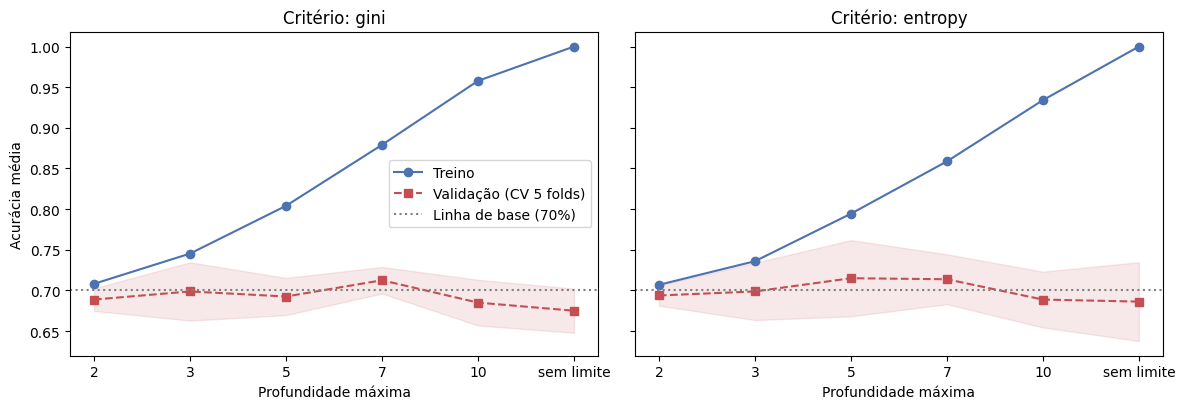

In [10]:
# gráfico: acurácia média de treino e de validação x profundidade (um painel por critério)
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
x = np.arange(len(profundidades))
for eixo, (c, tabela) in zip(eixos, res.items()):
    eixo.plot(x, tabela["acc_treino"], "o-", label="Treino", color="#4C72B0")
    eixo.plot(x, tabela["acc_val"], "s--", label="Validação (CV 5 folds)", color="#C44E52")
    eixo.fill_between(x, tabela["acc_val"] - tabela["desvio_val"], tabela["acc_val"] + tabela["desvio_val"], color="#C44E52", alpha=0.12)
    eixo.axhline(0.70, color="gray", ls=":", label="Linha de base (70%)")
    eixo.set_xticks(x); eixo.set_xticklabels(rotulos)
    eixo.set_xlabel("Profundidade máxima"); eixo.set_title(f"Critério: {c}")
eixos[0].set_ylabel("Acurácia média"); eixos[0].legend(loc="center right")
plt.tight_layout()
plt.show()

In [11]:
# melhor profundidade = maior acurácia média de validação (em empate, a árvore mais simples)
for c, tabela in res.items():
    i = int(np.argmax(np.isclose(tabela["acc_val"], tabela["acc_val"].max())))
    print(f"{c:8s} -> melhor profundidade = {tabela['max_depth'].iloc[i]} (validação = {tabela['acc_val'].iloc[i]:.4f}, treino = {tabela['acc_treino'].iloc[i]:.4f})")

# profundidade adotada daqui em diante: a do critério Gini
t = res["gini"]
i_best = int(np.argmax(np.isclose(t["acc_val"], t["acc_val"].max())))
BEST_DEPTH = profundidades[i_best]
print()
print("Profundidade adotada (critério Gini):", BEST_DEPTH)

gini     -> melhor profundidade = 7 (validação = 0.7125, treino = 0.8791)
entropy  -> melhor profundidade = 5 (validação = 0.7150, treino = 0.7944)

Profundidade adotada (critério Gini): 7


**Resposta.** A profundidade escolhida (critério Gini) é a de maior acurácia de validação, impressa acima (**7**).

- **Profundidade muito baixa (2):** a árvore é simples demais e erra tanto no treino quanto na validação, com acurácias baixas e próximas. É **underfitting** (viés alto): o modelo não captura a estrutura dos dados.
- **Profundidade muito alta / sem limite:** a acurácia de treino chega a 100% (a árvore memoriza os dados, inclusive o ruído), mas a de validação cai. É **overfitting** (variância alta). A distância entre a curva de treino e a de validação cresce com a profundidade.
- O ponto ótimo fica no meio, onde a validação é máxima.

**Gini × entropia.** As melhores acurácias de validação dos dois critérios são praticamente iguais (a diferença é menor que o desvio entre os folds), então **não há diferença relevante**: os dois critérios medem impureza de forma parecida e levam a árvores semelhantes. Observação: todas as acurácias de validação ficam perto da linha de base de 70%, o que mostra que o problema é difícil para uma árvore única.

## Tarefa 5 - Interpretação do modelo: usando a árvore com a profundidade escolhida, gere a visualização gráfica da árvore e a lista de importância dos atributos. Responda: quais são os três atributos mais determinantes para a classificação? Escreva, em linguagem natural, o conjunto de regras correspondente ao caminho que leva da raiz até a folha com maior número de amostras de mau risco.

Profundidade real: 7 | nº de folhas: 59


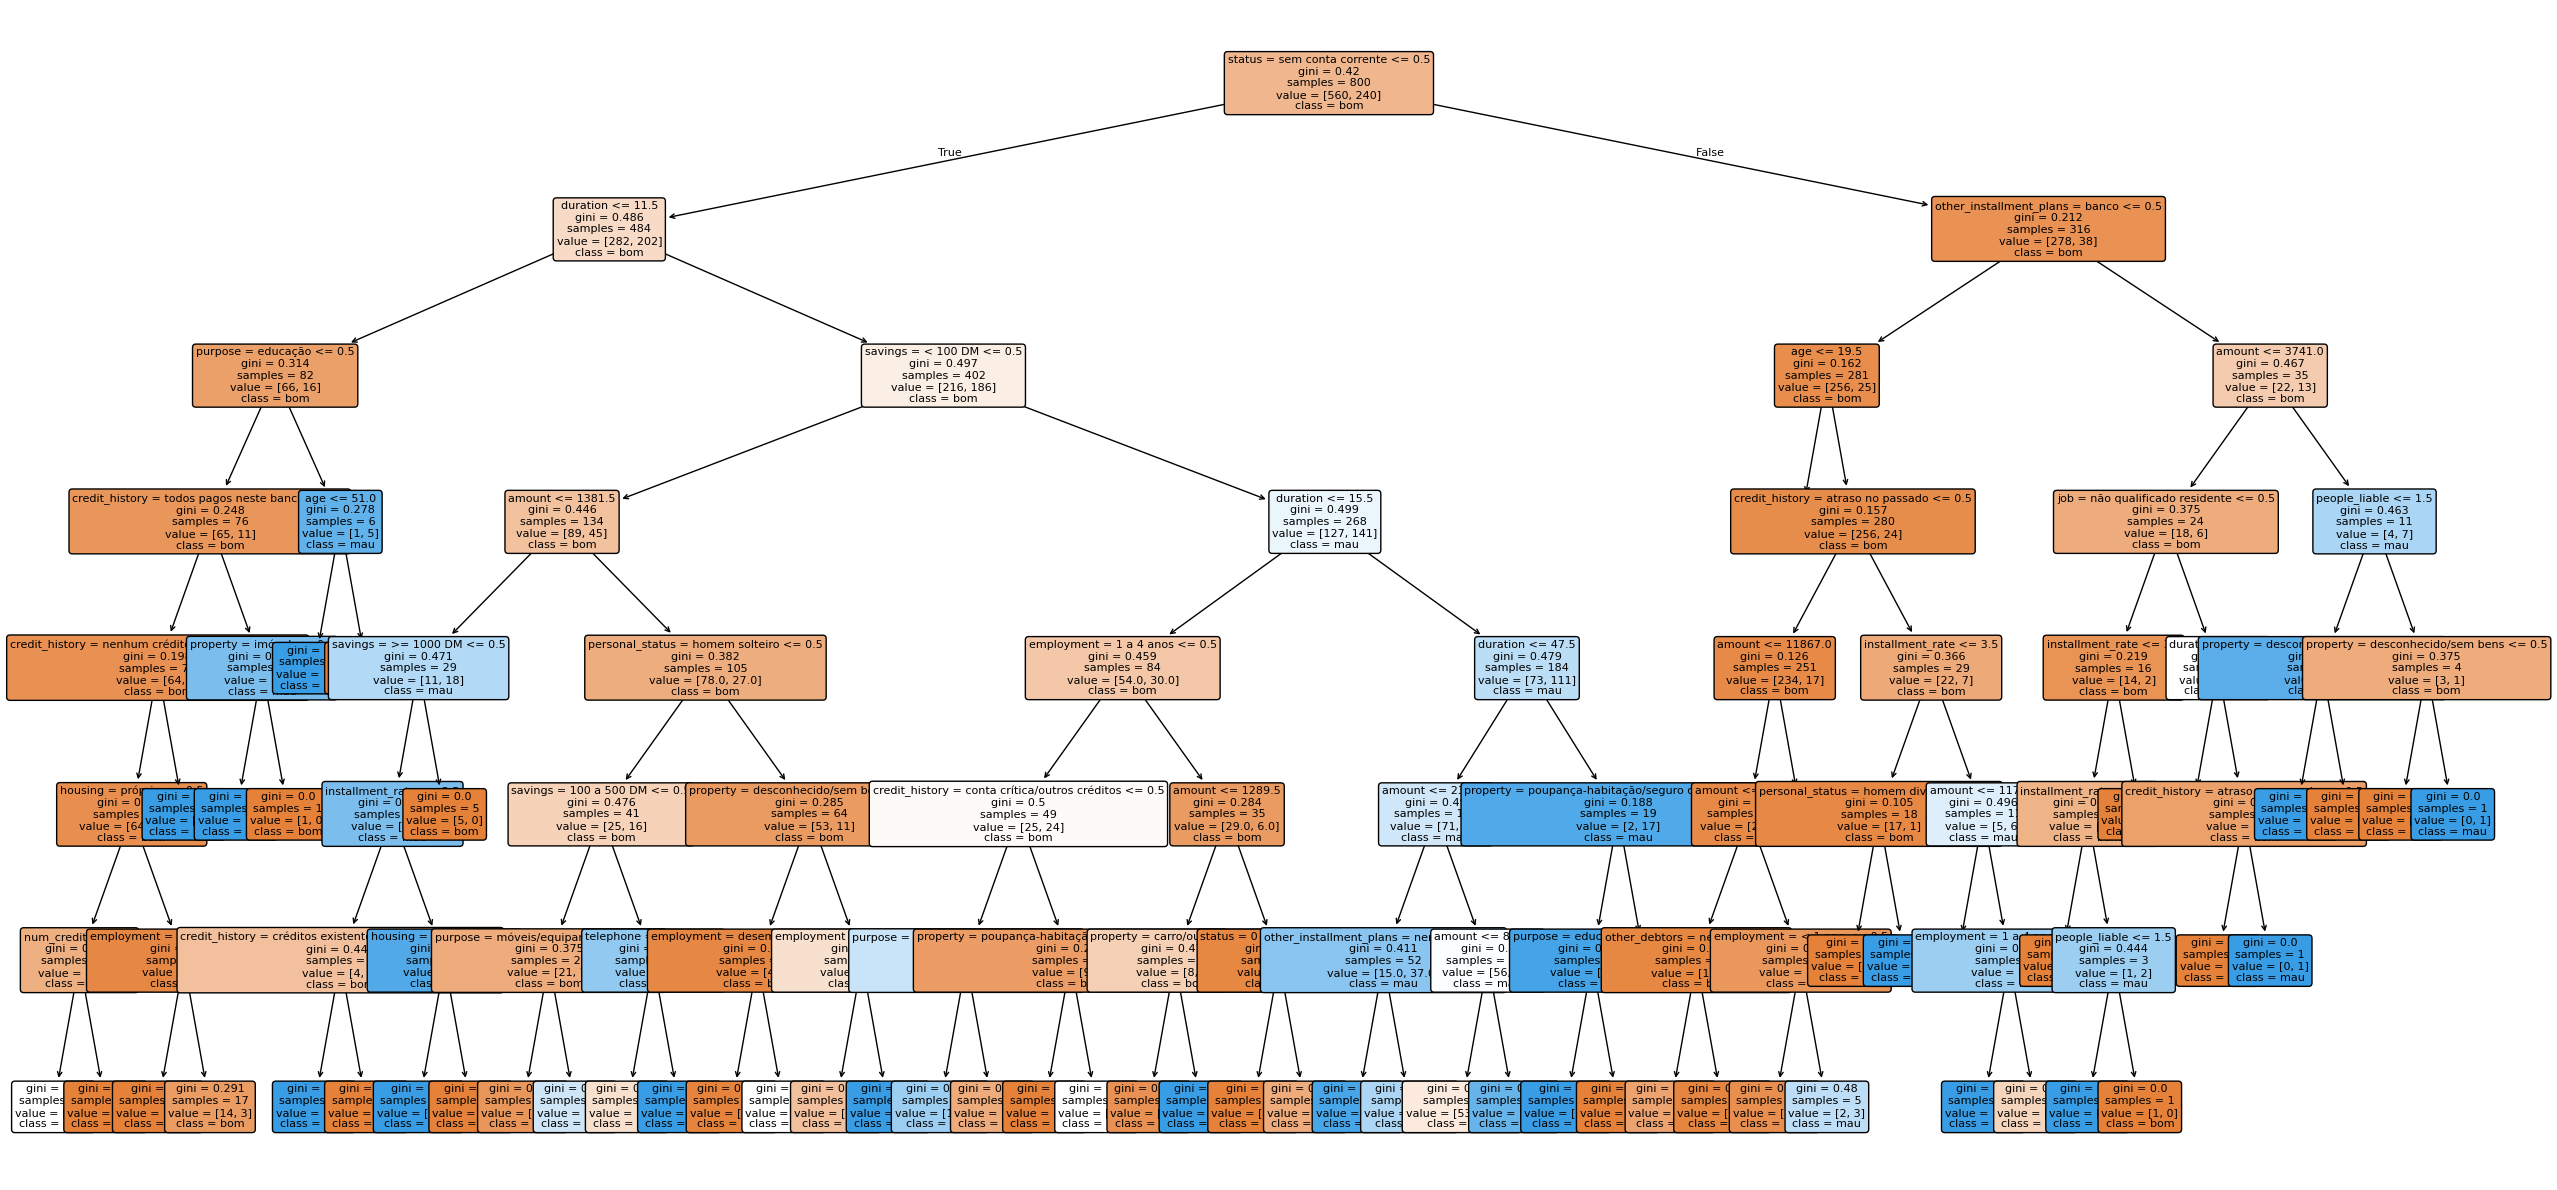

In [12]:
# árvore final: critério Gini e profundidade escolhida, treinada em todo o treino
arvore = DecisionTreeClassifier(max_depth=BEST_DEPTH, criterion="gini", random_state=SEED).fit(X_train, y_train)
print("Profundidade real:", arvore.get_depth(), "| nº de folhas:", arvore.get_n_leaves())

# visualização gráfica da árvore completa
plt.figure(figsize=(26, 12))
plot_tree(arvore, feature_names=list(X.columns), class_names=["bom", "mau"], filled=True, rounded=True, fontsize=8)
plt.tight_layout()
plt.show()

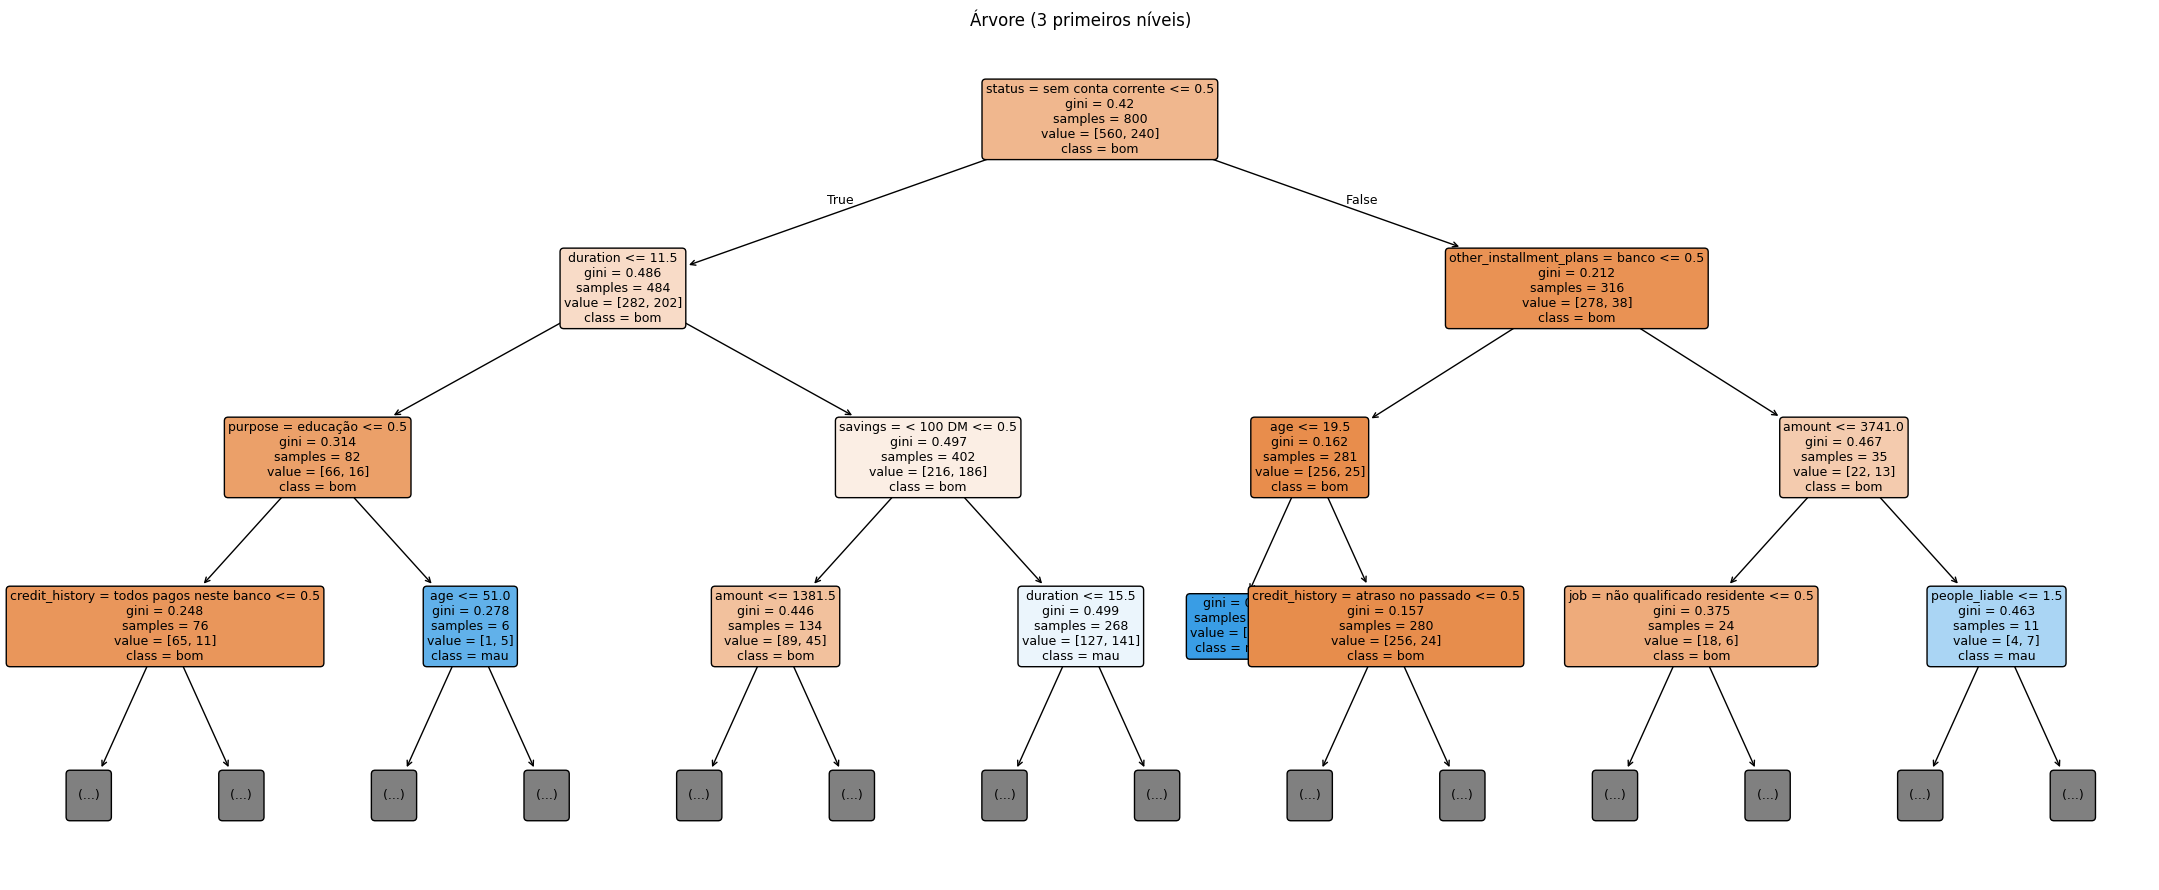

In [13]:
# versão legível: só os 3 primeiros níveis da mesma árvore
plt.figure(figsize=(22, 9))
plot_tree(arvore, max_depth=3, feature_names=list(X.columns), class_names=["bom", "mau"], filled=True, rounded=True, fontsize=9)
plt.title("Árvore (3 primeiros níveis)")
plt.tight_layout()
plt.show()

Top-10 colunas (após o one-hot):
status = sem conta corrente         0.1858
duration                            0.1252
amount                              0.1143
installment_rate                    0.0453
property = desconhecido/sem bens    0.0404
purpose = educação                  0.0394
employment = 1 a 4 anos             0.0357
savings = < 100 DM                  0.0356
other_installment_plans = banco     0.0273
savings = >= 1000 DM                0.0256

Importância por atributo original (os 3 primeiros são os mais determinantes):
status                     0.1881
duration                   0.1252
amount                     0.1143
property                   0.0890
savings                    0.0804
credit_history             0.0728
employment                 0.0655
purpose                    0.0621
installment_rate           0.0453
other_installment_plans    0.0373
housing                    0.0255
personal_status            0.0235
age                        0.0183
people_liable   

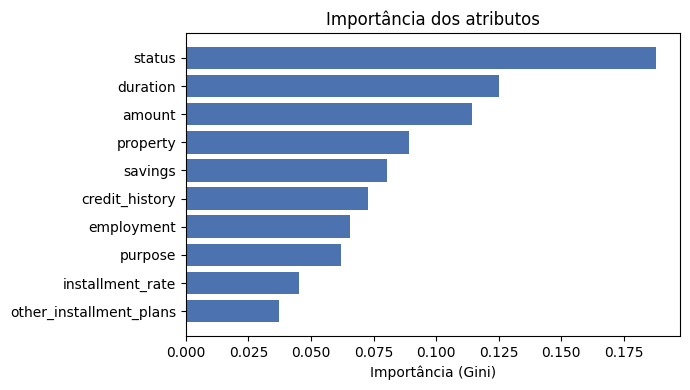

In [14]:
# importância dos atributos (redução total de impureza, normalizada: soma = 1)
imp = pd.Series(arvore.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top-10 colunas (após o one-hot):")
print(imp.head(10).round(4).to_string())

# soma das colunas one-hot de volta no atributo original (ex.: todas as colunas "status = ...")
original = lambda c: c.split(" = ")[0]
imp_attr = imp.groupby(original).sum().sort_values(ascending=False)
print()
print("Importância por atributo original (os 3 primeiros são os mais determinantes):")
print(imp_attr[imp_attr > 0].round(4).to_string())

top = imp_attr[imp_attr > 0].head(10)[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top.index, top.values, color="#4C72B0")
plt.xlabel("Importância (Gini)"); plt.title("Importância dos atributos")
plt.tight_layout()
plt.show()

In [15]:
# quantos exemplos de treino (maus e bons) caíram em cada folha
folhas_treino = arvore.apply(X_train)
tab = (pd.DataFrame({"folha": folhas_treino, "mau": y_train.values})
         .groupby("folha").agg(n=("mau", "size"), maus=("mau", "sum")))
tab["bons"] = tab["n"] - tab["maus"]
tab["%mau"] = tab["maus"] / tab["n"]
tab["classe_predita"] = np.where(tab["maus"] > tab["bons"], "mau", "bom")

# as folhas com mais maus pagadores
print(tab.sort_values("maus", ascending=False).head(6).to_string())

        n  maus  bons      %mau classe_predita
folha                                         
67     97    44    53  0.453608            bom
65     38    24    14  0.631579            mau
49     30    20    10  0.666667            mau
71     17    17     0  1.000000            mau
27     16    16     0  1.000000            mau
64     14    13     1  0.928571            mau


In [16]:
# reconstrói o caminho raiz -> folha a partir da estrutura interna da árvore
t = arvore.tree_
pai = {}   # para cada nó: (nó pai, lado "<=" ou ">")
for no in range(t.node_count):
    for filho, lado in ((t.children_left[no], "<="), (t.children_right[no], ">")):
        if filho != -1:
            pai[filho] = (no, lado)

def regras_da_folha(folha):
    # sobe da folha até a raiz coletando as condições e depois as coloca na ordem raiz -> folha
    passos, no = [], folha
    while no in pai:
        p, lado = pai[no]
        passos.append((X.columns[t.feature[p]], lado, t.threshold[p]))
        no = p
    passos = passos[::-1]
    regras, num = [], {}
    for feat, lado, thr in passos:
        if " = " in feat:                       # coluna one-hot (0/1): vira "atributo = categoria" ou "≠"
            a, cat = feat.split(" = ", 1)
            regras.append(f"{a} = '{cat}'" if lado == ">" else f"{a} ≠ '{cat}'")
        else:                                   # numérico: junta as condições do mesmo atributo em um intervalo
            lo, hi = num.get(feat, (-np.inf, np.inf))
            num[feat] = (max(lo, thr), hi) if lado == ">" else (lo, min(hi, thr))
    for feat, (lo, hi) in num.items():
        if np.isinf(lo):
            regras.append(f"{feat} ≤ {hi:.1f}")
        elif np.isinf(hi):
            regras.append(f"{feat} > {lo:.1f}")
        else:
            regras.append(f"{lo:.1f} < {feat} ≤ {hi:.1f}")
    return regras

def mostra(folha, titulo):
    r = tab.loc[folha]
    print(f"{titulo} (folha {folha}: {int(r['maus'])} maus e {int(r['bons'])} bons = {r['%mau']:.0%} maus; classe predita = {r['classe_predita']})")
    for i, regra in enumerate(regras_da_folha(folha), 1):
        print(f"  {i}. {regra}")
    print()

# (A) folha com o maior número absoluto de maus pagadores
mostra(tab["maus"].idxmax(), "Folha com mais maus pagadores")

# (B) entre as folhas que PREVEEM "mau", a que tem mais maus pagadores
mostra(tab[tab["classe_predita"] == "mau"]["maus"].idxmax(), "Folha 'mau' com mais maus pagadores")

Folha com mais maus pagadores (folha 67: 44 maus e 53 bons = 45% maus; classe predita = bom)
  1. status ≠ 'sem conta corrente'
  2. savings = '< 100 DM'
  3. 15.5 < duration ≤ 47.5
  4. 2321.0 < amount ≤ 8015.5

Folha 'mau' com mais maus pagadores (folha 65: 24 maus e 14 bons = 63% maus; classe predita = mau)
  1. status ≠ 'sem conta corrente'
  2. savings = '< 100 DM'
  3. other_installment_plans = 'nenhum'
  4. 15.5 < duration ≤ 47.5
  5. amount ≤ 2321.0



**Resposta.** Árvore final: critério Gini, profundidade 7 (gráficos acima: a árvore completa e a versão com os 3 primeiros níveis, mais legível).

**Os três atributos mais determinantes** (importância somada das colunas one-hot de cada atributo, tabela impressa acima): **`status`** (saldo da conta corrente), **`duration`** (duração do empréstimo em meses) e **`amount`** (valor solicitado). `status` é a raiz da árvore: a pergunta sobre a conta corrente é a que mais separa bons e maus pagadores.

**Regras do caminho até a folha com mais maus pagadores** (a folha A impressa acima, com 44 maus e 53 bons no treino): como os bons são maioria nela, a folha prevê *bom*, mas é a que concentra mais maus em números absolutos. Em linguagem natural:

> SE o cliente **tem conta corrente** (status diferente de "sem conta corrente") **E** poupança **< 100 DM** **E** duração do empréstimo **entre 15,5 e 47,5 meses** **E** valor solicitado **entre 2.321 e 8.015,5 DM** → 97 amostras, 44 maus pagadores (45%).

Já a folha que **prevê "mau"** com mais maus pagadores (folha B: 24 maus e 14 bons, 63%) tem as regras:

> SE tem conta corrente **E** poupança < 100 DM **E** outros planos de parcelamento = "nenhum" **E** duração entre 15,5 e 47,5 meses **E** valor ≤ 2.321 DM → **mau pagador**.

## Tarefa 6 - Avaliação do modelo: utilizando o conjunto de teste, calcule a matriz de confusão e as métricas de acurácia, precisão, recall e F1-score para cada classe. Responda: qual tipo de erro o modelo comete com mais frequência e por que ele é o mais grave nesta aplicação? Que ajuste você faria no treinamento para reduzi-lo?

$$ Precisão = \frac{VP}{VP + FP} \qquad Recall = \frac{VP}{VP + FN} \qquad F1 = 2\,\frac{Precisão \cdot Recall}{Precisão + Recall} $$

Aqui a classe positiva é **mau pagador**. Então: **FP** = bom pagador recusado (perda de receita); **FN** = mau pagador aprovado (prejuízo direto).

          previsto bom  previsto mau
real bom           112            28
real mau            36            24
VN=112  FP=28  FN=36  VP=24


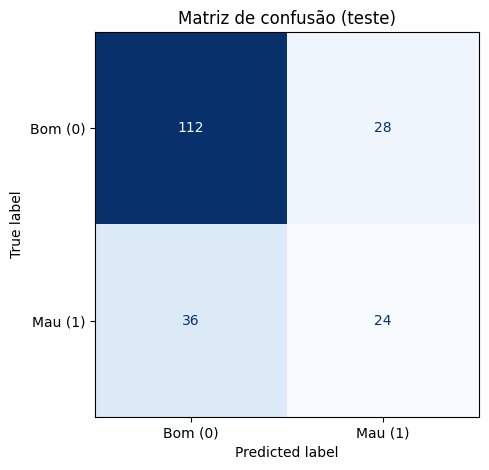

In [17]:
# previsões da árvore final no conjunto de teste
y_pred = arvore.predict(X_test)

# matriz de confusão (linhas = real, colunas = previsto)
cm = confusion_matrix(y_test, y_pred)
vn, fp, fn, vp = cm.ravel()
print(pd.DataFrame(cm, index=["real bom", "real mau"], columns=["previsto bom", "previsto mau"]))
print(f"VN={vn}  FP={fp}  FN={fn}  VP={vp}")

ConfusionMatrixDisplay(cm, display_labels=["Bom (0)", "Mau (1)"]).plot(cmap="Blues", colorbar=False)
plt.grid(False); plt.title("Matriz de confusão (teste)")
plt.tight_layout()
plt.show()

In [18]:
# acurácia, e precisão / recall / F1 de cada classe
print(f"Acurácia (teste): {accuracy_score(y_test, y_pred):.4f}  (linha de base = {(y_test == 0).mean():.2f})")
print()
print(classification_report(y_test, y_pred, target_names=["bom pagador", "mau pagador"], digits=4))

Acurácia (teste): 0.6800  (linha de base = 0.70)

              precision    recall  f1-score   support

 bom pagador     0.7568    0.8000    0.7778       140
 mau pagador     0.4615    0.4000    0.4286        60

    accuracy                         0.6800       200
   macro avg     0.6091    0.6000    0.6032       200
weighted avg     0.6682    0.6800    0.6730       200



**Resposta.** A acurácia fica **abaixo da linha de base** de 70% (aprovar todo mundo); o valor do modelo só aparece no recall da classe "mau", que é baixo.

**Erro mais frequente e mais grave:** o **falso negativo**: um mau pagador classificado como bom, ou seja, **crédito aprovado para quem não vai pagar**. Na matriz acima há mais FN que FP, e o recall da classe "mau" mostra que o modelo deixa passar a maior parte dos maus. O FN é o mais grave porque gera prejuízo direto (perde-se o valor emprestado), enquanto o FP só gera perda de receita (o `german.doc` informa que errar um mau pagador custa 5 vezes mais que recusar um bom).

**Ajuste proposto:** dar mais peso à classe "mau" no treinamento (`class_weight`), para que a árvore penalize mais os FN. O peso é escolhido por validação cruzada **no treino**, sem olhar o teste, pelo custo do `german.doc`: custo = 5·FN + FP.

In [19]:
from sklearn.model_selection import cross_val_predict

# pesos testados para a classe "mau" (1); a classe "bom" (0) fica sempre com peso 1
pesos = {"sem peso": None, "peso 2": {0: 1, 1: 2}, "peso 3": {0: 1, 1: 3},
         "peso 5 (matriz de custos)": {0: 1, 1: 5}, "balanced": "balanced"}

linhas = []
for nome, cw in pesos.items():
    arv = DecisionTreeClassifier(max_depth=BEST_DEPTH, criterion="gini", class_weight=cw, random_state=SEED)

    # custo na validação cruzada do TREINO (critério de escolha do peso)
    p_cv = cross_val_predict(arv, X_train, y_train, cv=cv)
    _, fp_cv, fn_cv, _ = confusion_matrix(y_train, p_cv).ravel()

    # treino completo e avaliação no teste
    arv.fit(X_train, y_train)
    yp = arv.predict(X_test)
    _, fp_t, fn_t, _ = confusion_matrix(y_test, yp).ravel()

    linhas.append({"configuração": nome, "CV custo (5FN+FP)": 5 * fn_cv + fp_cv,
                   "TESTE acurácia": accuracy_score(y_test, yp), "TESTE precisão(mau)": precision_score(y_test, yp),
                   "TESTE recall(mau)": recall_score(y_test, yp), "TESTE F1(mau)": f1_score(y_test, yp),
                   "FN": fn_t, "FP": fp_t, "TESTE custo": 5 * fn_t + fp_t})

comp = pd.DataFrame(linhas).set_index("configuração")
print(comp.round(3).to_string())
print()
print("Peso com menor custo na validação cruzada do treino:", comp["CV custo (5FN+FP)"].idxmin())

                           CV custo (5FN+FP)  TESTE acurácia  TESTE precisão(mau)  TESTE recall(mau)  TESTE F1(mau)  FN  FP  TESTE custo
configuração                                                                                                                            
sem peso                                 686            0.68                0.462              0.400          0.429  36  28          208
peso 2                                   654            0.60                0.386              0.567          0.459  26  54          184
peso 3                                   573            0.60                0.391              0.600          0.474  24  56          176
peso 5 (matriz de custos)                514            0.60                0.412              0.783          0.540  13  67          132
balanced                                 611            0.58                0.370              0.567          0.447  26  58          188

Peso com menor custo na validação cruzad

**Conclusão do ajuste.** O peso com menor custo na validação cruzada (peso 5, o da matriz de custos) reduz bastante os falsos negativos no teste e o custo total, ao preço de mais falsos positivos e menor acurácia: é o *trade-off* entre precisão e recall. Em crédito, esse trade-off compensa, porque um FN custa 5 vezes mais que um FP. Outras opções de ajuste: diminuir o limiar de decisão em `predict_proba`, ou controlar a complexidade com `min_samples_leaf` / poda (`ccp_alpha`).